# Viscosity model comparison - XGBoost vs others

Can batch process features predict Press 1 **Viscosity**, which model does it best, and which X matter?

- Data: `../Digester_Analysis/data/batch_master.csv` (1 row = 1 batch). **No PI access.**
- Validation: `TimeSeriesSplit` - always train on the past, test on the future. Gate = R² ≥ 0.30.
- **To add / remove a tag: edit `FEATURES` in `config.py`, then Restart & Run All.**
- Charts are saved to `output/` (git-ignored).

In [19]:
import importlib
import pandas as pd

import config, data, models, explain, plots
for mod in (config, data, models, explain, plots):   # pick up edits without restarting the kernel
    importlib.reload(mod)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Feature coverage
Every feature from `config.FEATURES`: does the column exist, and how many batches per digester have it?
Need a column name? Run `data.list_columns("alkali")`.

In [20]:
data.coverage()

rows: 3105 batches -> 366 with a Viscosity result after filters


,feature,label,status,pct_nan,n_D1,n_D2,n_D3,n_D4
0,alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,ok,0.0,89,103,91,83
1,pfactor_actual_last_prehydrolysis,P-factor,ok,0.0,89,103,91,83
2,heat_and_cook_minutes,H&C minutes,ok,0.0,89,103,91,83
3,white_liquor_per_ton_chip,WL / t chip,ok,0.0,89,103,91,83
4,liquor_to_wood_ratio,L:W,ok,0.0,89,103,91,83
5,LP_pressure_mean_heat_and_cook,LP pressure,ok,0.0,89,103,91,83
6,pfactor_rate,P-factor rate,ok,0.0,89,103,91,83
7,pfactor_temp_max_prehydrolysis,P-temp max,ok,0.0,89,103,91,83
8,pfactor_overshoot,P-factor overshoot,ok,0.0,89,103,91,83


In [21]:
df, feats = data.build_xy()
feats

rows: 3105 batches -> 366 with a Viscosity result after filters
rows with all 12 features: 366  (2026-08-01 .. 2026-10-15)


['alkali_accumulator1_conc_mean_hot_liquor_filling',
 'pfactor_actual_last_prehydrolysis',
 'heat_and_cook_minutes',
 'white_liquor_per_ton_chip',
 'liquor_to_wood_ratio',
 'LP_pressure_mean_heat_and_cook',
 'pfactor_rate',
 'pfactor_temp_max_prehydrolysis',
 'pfactor_overshoot',
 'is_D2',
 'is_D3',
 'is_D4']

## 2. Model leaderboard
Same rows, same time split for every model. `baseline` = predict the train mean (it can be < 0 when the mean drifts).

  scoring baseline       pooled
  scoring ridge          pooled
  scoring ridge          pooled + DigID
  scoring random_forest  pooled
  scoring random_forest  pooled + DigID
  scoring sklearn_gbm    pooled
  scoring sklearn_gbm    pooled + DigID
  scoring xgboost        pooled
  scoring xgboost        pooled + DigID
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\leaderboard.png


,model,type,features,R2,MAE,n_test,pass_gate
0,ridge,linear,pooled,0.110,28.7,273,False
1,ridge,linear,pooled + DigID,0.109,28.6,273,False
2,random_forest,trees (bagging),pooled + DigID,0.047,29.8,273,False
3,random_forest,trees (bagging),pooled,0.046,29.8,273,False
4,xgboost,trees (boosting),pooled + DigID,0.025,30.8,273,False
5,xgboost,trees (boosting),pooled,0.023,30.7,273,False
6,sklearn_gbm,trees (boosting),pooled + DigID,0.020,30.8,273,False
7,sklearn_gbm,trees (boosting),pooled,0.018,30.7,273,False
8,baseline,mean of train,pooled,-0.535,41.0,273,False


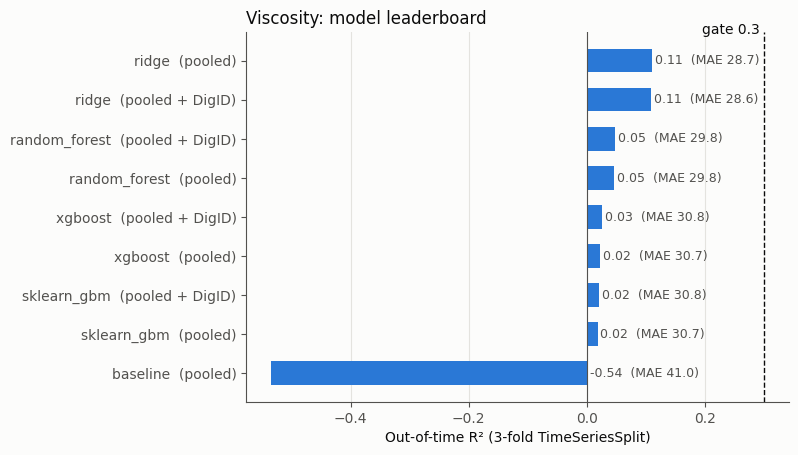

In [22]:
board = models.leaderboard(df, feats)
plots.leaderboard_bar(board)
board
#MAE (Mean Absolute Error) = ทายผิดเฉลี่ยกี่หน่วย
#R² (R-squared) = model อธิบายการแกว่งของ Viscosity ได้กี่เปอร์เซ็นต์

### Per-digester models (for comparison)
Each digester alone, process features only. Small n -> unstable; pooled is expected to win.

In [23]:
pd.concat([models.per_digester(df, feats, "ridge"), models.per_digester(df, feats, "xgboost")])

,digester,model,R2,MAE,n_batches,n_test
0,D1,ridge,0.076,26.2,89,66
1,D2,ridge,0.000,36.4,103,75
2,D3,ridge,-0.086,36.6,91,66
3,D4,ridge,-0.023,26.0,83,60
0,D1,xgboost,-0.176,32.2,89,66
1,D2,xgboost,-0.145,40.9,103,75
2,D3,xgboost,-0.031,35.8,91,66
3,D4,xgboost,-0.091,28.5,83,60


## 3. Feature effects - do the models agree?
- `direction` / `spearman`: sign of the link with Viscosity.
- `ridge_per_unit`: Viscosity change per 1 unit of X (linear, holding others fixed).
- `rf_perm`, `xgb_perm`: R² lost on the hold-out when X is shuffled.
- `xgb_shap`: mean |SHAP| in Viscosity units.
- `drop_one_dR2`: R² change when X is removed (negative = X helps).
- `rank`: mean rank of the four importance columns.

In [24]:
effects = explain.feature_effects(df, feats)
effects
# X ขยับ 1 → Y เปลี่ยนเท่าไร (เส้นตรง)
# rf_perm	สลับมั่วแล้ว Random Forest แย่ลงไหม
# xgb_perm	สลับมั่วแล้ว XGBoost แย่ลงไหม
# xgb_shap	เฉลี่ยดันค่าทำนายกี่หน่วย
# drop_one_dR2	ลบออกแล้ว R² เปลี่ยนไง

  direction + ridge
  permutation importance (random forest, xgboost)
  SHAP (xgboost)
  drop-one (xgboost, time split)


,label,spearman,direction,ridge_per_unit,rf_perm,xgb_perm,xgb_shap,drop_one_dR2,rank
alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,-0.58,-,-14.436,0.012,0.026,10.9,-0.148,2.0
pfactor_rate,P-factor rate,-0.42,-,-7.957,0.017,0.024,2.8,0.005,4.0
white_liquor_per_ton_chip,WL / t chip,-0.11,-,-151.474,-0.005,0.029,3.8,-0.024,4.8
pfactor_overshoot,P-factor overshoot,-0.22,-,-0.015,0.018,0.043,2.3,0.030,4.8
heat_and_cook_minutes,H&C minutes,-0.42,-,-0.600,0.002,0.015,2.2,-0.019,6.0
LP_pressure_mean_heat_and_cook,LP pressure,0.05,+,0.278,0.003,0.013,2.5,0.023,7.0
pfactor_actual_last_prehydrolysis,P-factor,-0.50,-,-0.210,0.002,-0.006,8.2,0.020,7.1
is_D3,D3,0.05,+,2.365,0.001,0.011,1.3,0.001,7.6
liquor_to_wood_ratio,L:W,0.17,+,12.459,0.007,0.016,0.9,0.033,7.8
pfactor_temp_max_prehydrolysis,P-temp max,-0.25,-,-0.848,-0.000,0.015,3.1,0.032,7.9


### SHAP summary (XGBoost, last 30% in time)
Each dot = one batch. Right = raises Viscosity; color = value of X (red high, blue low).

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\shap_summary.png


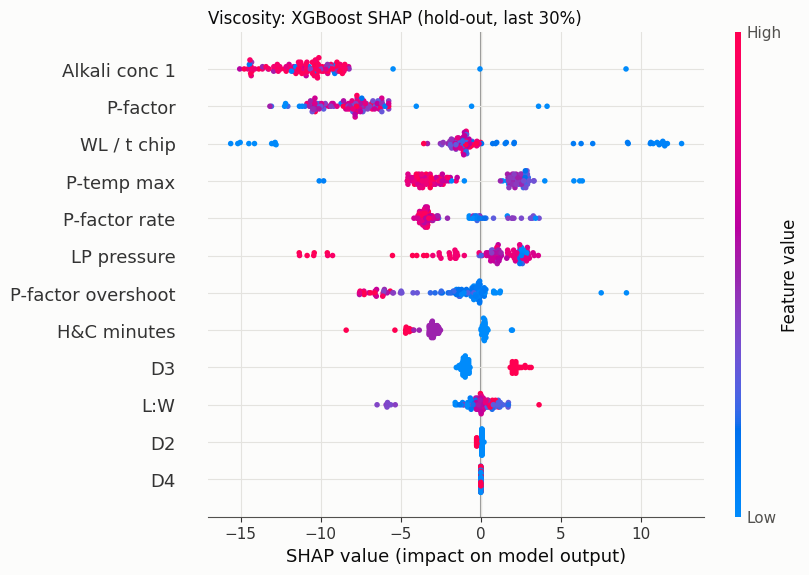

In [25]:
plots.shap_summary(df, feats);

### Partial dependence + plain binned means
PDP = model view; the quintile table = raw data view. They should tell the same story.

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\pdp_top.png
Alkali conc 1


,mean,count
alkali_accumulator1_conc_mean_hot_liquor_filling,,
"(34.781, 35.96]",806.6,74
"(35.96, 36.25]",805.7,73
"(36.25, 36.74]",792.8,73
"(36.74, 37.868]",764.1,73
"(37.868, 38.142]",741.6,73


P-factor rate


,mean,count
pfactor_rate,,
"(2.642, 3.958]",798.2,74
"(3.958, 4.189]",795.4,73
"(4.189, 4.462]",796.8,73
"(4.462, 4.816]",774.3,73
"(4.816, 6.024]",746.3,73


WL / t chip


,mean,count
white_liquor_per_ton_chip,,
"(0.099, 0.134]",786.4,74
"(0.134, 0.144]",786.2,73
"(0.144, 0.157]",787.2,73
"(0.157, 0.179]",778.0,73
"(0.179, 0.49]",773.4,73


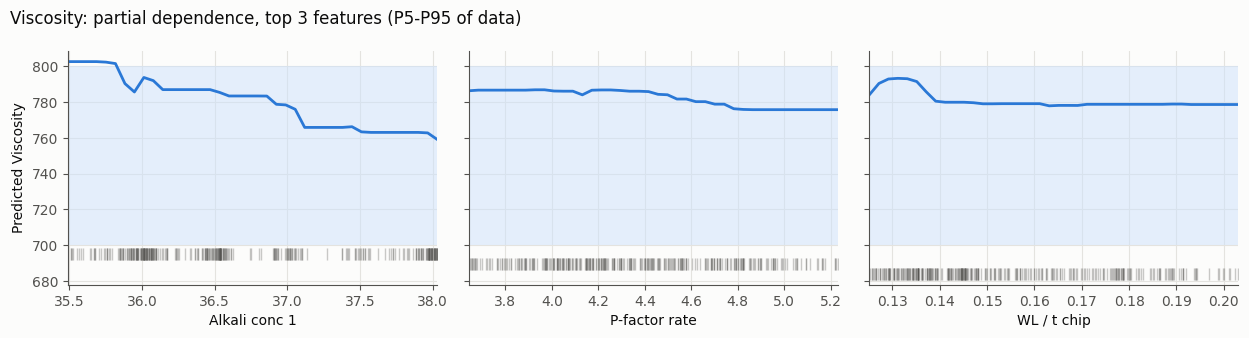

In [26]:
plots.pdp_top(df, feats, effects);
for f in [x for x in effects.index if not x.startswith("is_D")][:config.TOP_N_PDP]:
    print(data.label(f))
    display(explain.binned_means(df, f))

## 4. Actual vs predicted over time

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\pred_vs_actual_xgboost.png


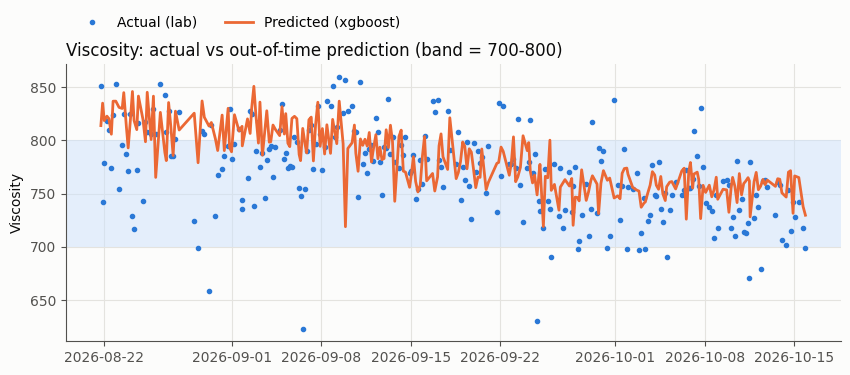

In [27]:
plots.predicted_vs_actual(df, models.time_split_predict(df, feats, "xgboost"), "xgboost");

## Reading the result
- Below the gate -> **do not optimize** on this model; use the feature table as hypotheses only.
- Trust a driver when several columns agree (sign + rank) and the binned means show the same shape.
- Log each run in `update.md` (What was done / Results / Found by).